# Mixed-mode delamination of AS4/PEEK: DCB, MMB and ENF tests of Reeder and Crews

P. P. Camanho, C. G. Dávila and M. F. de Moura, *Numerical simulation of mixed-mode progressive delamination in composite materials*, J. Compos. Mater. 2003; 37(16):1415-1438, https://doi.org/10.1177/0021998303034505.

A. Turon, P. P. Camanho, J. Costa and C. G. Dávila, *A damage model for the simulation of delamination in advanced composites under variable-mode loading*, Mech. Mater. 2006; 38(11):1072-1089, https://doi.org/10.1016/j.mechmat.2005.10.003.

Tests: J. R. Reeder and J. H. Crews, *Mixed-mode bending method for delamination testing*, AIAA J. 1990; 28(7):1270-1276, https://doi.org/10.2514/3.25204, and J. R. Reeder and J. H. Crews, Jr., *Nonlinear analysis and redesign of the mixed-mode bending delamination test*, NASA TM-102777, 1991.

Unidirectional AS4/PEEK (APC2) specimens tested in the double cantilever beam (DCB), mixed-mode bending (MMB) at $G_{II}/G$ = 20, 50 and 80% and end-notched flexure (ENF) configurations. Both papers model the five tests with three-dimensional cohesive (decohesion) elements in ABAQUS and plot the load-displacement curves of the tests with their analyses. The same group also analysed the MMB at 50% with shell elements: C. G. Dávila, P. P. Camanho and A. Turon, *Effective simulation of delamination in aeronautical structures using shells and cohesive elements*, J. Aircraft 2008; 45(2):663-672, https://doi.org/10.2514/1.32832.

`panels` models the five tests with the coupons of `panels.multidomain.delamination.create_coupon`, two plate arms joined by the mixed-mode bilinear cohesive law (theory: [mixed-mode cohesive zone](../cohesive_zone_mixed_mode.rst)), with CLPT and with FSDT arms. Linear elastic fracture mechanics (LEFM), the corrected beam theory of ASTM D6671/D6671M-22, is computed here as a third reference.

In [1]:
%matplotlib inline
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, os.path.abspath('.'))
import mmb_utils as mu
from panels.multidomain.connections.czm import BilinearLaw

# True runs panels and saves the results in RESULTS, False loads them
RERUN = bool(int(os.environ.get('MMB_RERUN', '0')))
RESULTS = 'results'
REFERENCE = os.path.join('reference_data', 'case1_as4peek')
# comma-separated keys, e.g. MMB50_clpt, runs only these (used to run in parallel)
ONLY = os.environ.get('MMB_TESTS')
ONLY = ONLY.split(',') if ONLY else None

## Specimen and material data

- Ply properties, Camanho et al. (2003), Table 1, p. 1429, and Turon et al. (2006), Table 1, p. 1080: $E_{11}$ = 122.7 GPa, $E_{22} = E_{33}$ = 10.1 GPa, $G_{12} = G_{13}$ = 5.5 GPa, $G_{23}$ = 3.7 GPa, $\nu_{12} = \nu_{13}$ = 0.25, $\nu_{23}$ = 0.45. Reeder's reports give other values of $E_{11}$ (116-129 GPa); 122.7 GPa is the value of both analyses.
- Specimen, Camanho et al. (2003), p. 1429: width 25.4 mm, two arms of 1.56 mm, 102 mm long. The arms have 12 plies (24 in the specimen, Reeder and Crews 1991, p. 7 of the PDF); the ply thickness, 0.13 mm, is inferred, the papers do not print it.
- Crack lengths, Camanho et al. (2003), Table 2, p. 1430: $a_0$ = 32.9 (DCB), 33.7 (MMB 20%), 34.1 (MMB 50%), 31.4 (MMB 80%) and 39.3 mm (ENF; 39.2 mm in Turon et al. 2006, Table 2).
- MMB apparatus: half-span $L$ = 50.8 mm (2 in, Reeder and Crews 1991, p. 7 of the PDF; neither paper prints it); lever lengths $c$ = 109.4, 44.4 and 28.4 mm, the numerical values of Camanho et al. (2003), Table 4, p. 1432, from simple beam theory and without the lever weight, which is not modelled here either. The ENF is assumed to be the MMB apparatus with $c = 0$ and the same $L$.
- Interface, Camanho et al. (2003), Tables 1-2, pp. 1429-1430, and Turon et al. (2006), Table 1, p. 1080: $G_{Ic}$ = 0.969 N/mm, $G_{IIc}$ = 1.719 N/mm, Benzeggagh-Kenane exponent $\eta$ = 2.284 (least-squares fit of the toughnesses of Table 2, Camanho et al. 2003, p. 1430), strengths $\tau_I$ = 80 MPa and $\tau_{II}$ = 100 MPa.
- Penalty stiffness: both papers use $K = 10^6$ N/mm$^3$ (Camanho et al. 2003, p. 1429). `panels` uses $k_I = 10^5$ N/mm$^3$, the value with which A. Turon, E. V. González, C. Sarrado, G. Guillamet and P. Maimí, *Accurate simulation of delamination under mixed-mode loading using a cohesive model with a mode-dependent penalty stiffness*, Compos. Struct. 2018; 184:506-511, https://doi.org/10.1016/j.compstruct.2017.10.017, analysed the MMB test of this material, and the shear stiffness $k_{sh}$ that makes the law consistent, $G_{Ic}/G_{oI} = G_{IIc}/G_{oII}$, i.e. `BilinearLaw(..., KII=None)`. With $10^6$ N/mm$^3$, the sliding of the arms ahead of the crack decays at a rate of about 6 mm$^{-1}$ and would need cohesive domains of about 3 mm.

In [2]:
laminaprop = (122700., 10100., 0.25, 5500., 5500., 3700.)   # E11, E22, nu12, G12, G13, G23
plyt, stack = 0.13, [0]*12                                  # arm: 12 plies, h = 1.56 mm
b, L_dcb = 25.4, 102.
GIc, GIIc, eta, tauI, tauII, KI = 0.969, 1.719, 2.284, 80., 100., 1.e5
law = BilinearLaw(GIc, GIIc, tauI, tauII, KI, eta)
print(law)

# B = G_II/G (nominal), a0, L, c; delta_max: last load-point displacement of the runs
tests = {
    'DCB':   dict(kind='DCB', B=0.0, a0=32.9, x_end=L_dcb, delta_max=8.4267),
    'MMB20': dict(kind='MMB', B=0.2, a0=33.7, L=50.8, c=109.4, delta_max=13.1064),
    'MMB50': dict(kind='MMB', B=0.5, a0=34.1, L=50.8, c=44.4, delta_max=10.3318),
    'MMB80': dict(kind='MMB', B=0.8, a0=31.4, L=50.8, c=28.4, delta_max=9.7598),
    'ENF':   dict(kind='ENF', B=1.0, a0=39.3, L=50.8, delta_max=7.2922),
}

BilinearLaw(GIc=0.969, GIIc=1.719, tauI=80.0, tauII=100.0, KI=100000.0, eta=2.284, KII=88078.09773123909)


## Reference data

**Peak loads**, exact values of Table 3 of Camanho et al. (2003), p. 1431, and of Table 3 of Turon et al. (2006), p. 1085. The two tables give different experimental values for the DCB (147.1 and 147.5 N) and the ENF (734.0 and 748.4 N); the curves of the tests plotted by Turon et al. (2006) peak at 147.5 and 748.5 N. The peak of the shell model of Dávila et al. (2008) is read from their Fig. 6.

**Load-displacement curves**, digitised from the figures, with the displacement of the load point in every figure:

- tests and FE analysis of Turon et al. (2006), Figs. 9-13, pp. 1083-1085, read from the vector drawing of the figures, to 0.01 mm and 0.3 N; the FE curve of the MMB at 20% is the dashed line of Fig. 10, which holds every point of the analysis (its markers stop at 97.7 N);
- FE analysis of Camanho et al. (2003), Fig. 6, p. 1430, read from the raster image, $\pm$0.03 mm and $\pm$2 N;
- shell model of Dávila et al. (2008), Fig. 6, MMB at 50%, vector drawing, $\pm$0.02 mm and $\pm$0.9 N.

The tests plotted are not the raw records but readings of these figures. The unloading branches of the test curves are not shown.

In [3]:
# peak loads (N): (source, kind, value)
ref_peaks = {
    'DCB':   [('Test, Camanho 2003 Table 3', 'test', 147.1), ('Test, Turon 2006 Table 3', 'test', 147.5),
              ('FE, Camanho 2003 Table 3', 'FE', 155.3), ('FE, Turon 2006 Table 3', 'FE', 152.4)],
    'MMB20': [('Test, Camanho 2003 / Turon 2006 Table 3', 'test', 108.1),
              ('FE, Camanho 2003 Table 3', 'FE', 99.9), ('FE, Turon 2006 Table 3', 'FE', 100.5)],
    'MMB50': [('Test, Camanho 2003 Table 3', 'test', 275.4), ('Test, Turon 2006 Table 3', 'test', 275.3),
              ('FE, Camanho 2003 Table 3', 'FE', 274.5), ('FE, Turon 2006 Table 3', 'FE', 263.9),
              ('FE shells, Davila 2008 Fig. 6', 'FE', 266.5)],
    'MMB80': [('Test, Camanho 2003 / Turon 2006 Table 3', 'test', 518.7),
              ('FE, Camanho 2003 Table 3', 'FE', 502.0), ('FE, Turon 2006 Table 3', 'FE', 496.9)],
    'ENF':   [('Test, Camanho 2003 Table 3', 'test', 734.0), ('Test, Turon 2006 Table 3', 'test', 748.4),
              ('FE, Camanho 2003 Table 3', 'FE', 697.6), ('FE, Turon 2006 Table 3', 'FE', 697.1)],
}

# digitised curves: label -> file in REFERENCE
fig_turon = {'DCB': 'Fig9_DCB', 'MMB20': 'Fig10_MMB20', 'MMB50': 'Fig11_MMB50',
             'MMB80': 'Fig12_MMB80', 'ENF': 'Fig13_ENF'}
ref_curves = {}
for key, f in fig_turon.items():
    num = 'Turon2006_{0}_numerical{1}'.format(f, '_dashedline' if key == 'MMB20' else '')
    ref_curves[key] = {
        'Test (Turon 2006, Fig. {0})'.format(f[3:].split('_')[0]): ('Turon2006_{0}_experimental'.format(f), 'test'),
        'FE, Turon 2006': (num, 'FE'),
        'FE, Camanho 2003': ('Camanho2003_Fig6_{0}_numerical'.format(key), 'FE'),
    }
ref_curves['MMB50']['FE shells, Davila 2008'] = ('Davila2008_Fig6_MMB50_shell', 'FE')
curves = {key: {label: mu.read_curve(os.path.join(REFERENCE, f + '.csv'), loading_only=(k == 'test')) + (k,)
                for label, (f, k) in d.items()} for key, d in ref_curves.items()}

## Linear elastic fracture mechanics

Corrected beam theory of ASTM D6671/D6671M-22 (`mmb_utils.lefm_curve`): the compliance of Eq. 10 and the energy release rates of Eqs. 12-13 with the crack length correction $\chi h$ of Sec. 3.3 (mode I) and $0.42\chi h$ (mode II); the DCB and the ENF are the mode I and mode II parts of these equations. Self-similar growth at the toughness of the Benzeggagh-Kenane criterion at the nominal mode ratio, $G_c = G_{Ic} + (G_{IIc} - G_{Ic}) B^\eta$, up to $a = L$.

In [4]:
E11, E22, _, _, G13, _ = laminaprop
h = plyt*len(stack)
print('chi = {0:.3f}, chi h = {1:.3f} mm'.format(mu.chi(E11, E22, G13), mu.chi(E11, E22, G13)*h))
lefm = {}
for key, t in tests.items():
    Gc = mu.bk(GIc, GIIc, eta, t['B'])
    lefm[key] = mu.lefm_curve(t['kind'], E11, E22, G13, b, h, t['a0'], Gc, L=t.get('L'), c=t.get('c', 0.))
    if t['kind'] == 'MMB':
        print('{0}: lever length of D6671 Eq. 5 for B = {1}: {2:.1f} mm (used: {3} mm)'.format(
              key, t['B'], mu.lever_length(t['B'], t['a0'], h, mu.chi(E11, E22, G13), t['L']), t['c']))

chi = 1.709, chi h = 2.666 mm
MMB20: lever length of D6671 Eq. 5 for B = 0.2: 100.7 mm (used: 109.4 mm)
MMB50: lever length of D6671 Eq. 5 for B = 0.5: 42.8 mm (used: 44.4 mm)
MMB80: lever length of D6671 Eq. 5 for B = 0.8: 27.8 mm (used: 28.4 mm)


## panels model

Coupons of `create_coupon` (see its docstring for the supports, the lever and the load): each arm is a cracked domain, seven cohesive domains over 67.5 mm from the crack tip and, where the bonded length is longer, a far domain with the same cohesive law; contact over the pre-crack; domains joined with the null-space method. The lever constraint of the MMB acts on the mean deflections across the width. The DCB has the slope of the upper arm zero at the far end, 102 mm from the load line.

Discretisation, as in the study of the mixed-mode model (rules in `mmb_utils.discretisation`):

- $m$ = 24 terms along $x$ in each cohesive domain of 9.64 mm, $1.25\,r L_{dom}$ with $r = \max(\lambda_I, \mu)$ the larger of the decay rates of the opening and of the sliding of CLPT arms; the same terms are used for the FSDT arms;
- 240 Gauss points along $x$ per cohesive domain, about 18 per cohesive zone length $l_{cz} = 0.88 E_{22} G_{Ic}/\tau_I^2 = 1.35$ mm; 6 across the width; $n = 4$ terms across the width; 10 terms along $x$ in the cracked and far domains.

Solver (`solve_coupon`): Newton-Raphson, displacement increments of 0.1 mm (the largest; cut automatically down to $10^{-5}$ mm), relative tolerance $10^{-9}$; for the MMB at 80%, control of the separation at the load line (`control='load-line'`), which follows the snap-back after the peak, up to a crack length of 55 mm. The last displacement is twice the displacement at the LEFM peak (DCB, MMB 50 and 80%, ENF); for the MMB at 20% it is 13.1 mm. The peak loads are taken before the crack reaches the saddle, $a < L$. The ten runs were made at the same time on one computer, one thread each; the table at the end gives their run times.

In [5]:
L_coh, nd = 67.5, 7
disc = mu.discretisation(laminaprop, h, [law], L_coh, nd, model='clpt', nr_x_gauss=240)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in disc.items()})


def inputs_of(key, model):
    t = tests[key]
    inp = dict(kind=t['kind'], laminaprop=laminaprop, plyt=plyt, stack=stack, b=b, a0=t['a0'],
               laws=[mu.law_dict(law)], model=model, nd=nd, L_coh=L_coh, m_crack=10,
               m_coh=disc['m_coh'], m_far=10, n=4, nr_x_gauss=disc['nr_x_gauss'], nr_y_gauss=6)
    if t['kind'] == 'DCB':
        inp['x_end'] = t['x_end']
    else:
        inp['L'] = t['L']
        if t['kind'] == 'MMB':
            inp['c'] = t['c']
    return inp


def solver_of(key):
    s = dict(delta_max=tests[key]['delta_max'], inc=0.1, min_inc=1e-5, relTOL=1e-9)
    if key == 'MMB80':
        s.update(control='load-line', a_stop=55.)
    return s


runs = {}
for key in tests:
    for model in ('fsdt', 'clpt'):
        name = '{0}_{1}'.format(key, model)
        if ONLY is not None and name not in ONLY:
            continue
        path = os.path.join(RESULTS, 'mmb_camanho2003_as4peek_{0}.npz'.format(name))
        runs[name] = mu.run_or_load(inputs_of(key, model), solver_of(key), path, rerun=RERUN)

{'lambda_I': 1.065, 'mu': 1.919, 'r_fast_fsdt': 0.0, 'l_cz': 1.346, 'L_dom': 9.643, 'nd': 7, 'm_coh': 24, 'nr_x_gauss': 240}


## Results

Peak loads: references, LEFM and `panels`; the differences are to LEFM.

In [6]:
rows = []
for key, t in tests.items():
    for s, k, p in ref_peaks[key]:
        rows.append((key, s, p))
    rows.append((key, 'LEFM (ASTM D6671)', float(lefm[key][1].max())))
    for model in ('fsdt', 'clpt'):
        res = runs.get('{0}_{1}'.format(key, model))
        if res is not None:
            rows.append((key, 'panels ' + model.upper(), mu.peak_load(res, t.get('L'))[0]))
display(Markdown(mu.peaks_table(rows, ref='LEFM (ASTM D6671)')))

| test | source | $P_{max}$ (N) | vs LEFM (ASTM D6671) |
|---|---|---|---|
| DCB | Test, Camanho 2003 Table 3 | 147.1 | +6.2% |
| DCB | Test, Turon 2006 Table 3 | 147.5 | +6.5% |
| DCB | FE, Camanho 2003 Table 3 | 155.3 | +12.1% |
| DCB | FE, Turon 2006 Table 3 | 152.4 | +10.0% |
| DCB | LEFM (ASTM D6671) | 138.5 | - |
| DCB | panels FSDT | 135.7 | -2.0% |
| DCB | panels CLPT | 139.9 | +1.0% |
| MMB20 | Test, Camanho 2003 / Turon 2006 Table 3 | 108.1 | +19.6% |
| MMB20 | FE, Camanho 2003 Table 3 | 99.9 | +10.5% |
| MMB20 | FE, Turon 2006 Table 3 | 100.5 | +11.2% |
| MMB20 | LEFM (ASTM D6671) | 90.4 | - |
| MMB20 | panels FSDT | 89.4 | -1.1% |
| MMB20 | panels CLPT | 91.0 | +0.7% |
| MMB50 | Test, Camanho 2003 Table 3 | 275.4 | +7.2% |
| MMB50 | Test, Turon 2006 Table 3 | 275.3 | +7.2% |
| MMB50 | FE, Camanho 2003 Table 3 | 274.5 | +6.9% |
| MMB50 | FE, Turon 2006 Table 3 | 263.9 | +2.8% |
| MMB50 | FE shells, Davila 2008 Fig. 6 | 266.5 | +3.8% |
| MMB50 | LEFM (ASTM D6671) | 256.8 | - |
| MMB50 | panels FSDT | 252.3 | -1.8% |
| MMB50 | panels CLPT | 254.8 | -0.8% |
| MMB80 | Test, Camanho 2003 / Turon 2006 Table 3 | 518.7 | +7.9% |
| MMB80 | FE, Camanho 2003 Table 3 | 502.0 | +4.4% |
| MMB80 | FE, Turon 2006 Table 3 | 496.9 | +3.3% |
| MMB80 | LEFM (ASTM D6671) | 480.9 | - |
| MMB80 | panels FSDT | 461.4 | -4.0% |
| MMB80 | panels CLPT | 464.7 | -3.4% |
| ENF | Test, Camanho 2003 Table 3 | 734.0 | -2.1% |
| ENF | Test, Turon 2006 Table 3 | 748.4 | -0.2% |
| ENF | FE, Camanho 2003 Table 3 | 697.6 | -7.0% |
| ENF | FE, Turon 2006 Table 3 | 697.1 | -7.0% |
| ENF | LEFM (ASTM D6671) | 749.8 | - |
| ENF | panels FSDT | 717.5 | -4.3% |
| ENF | panels CLPT | 719.4 | -4.0% |

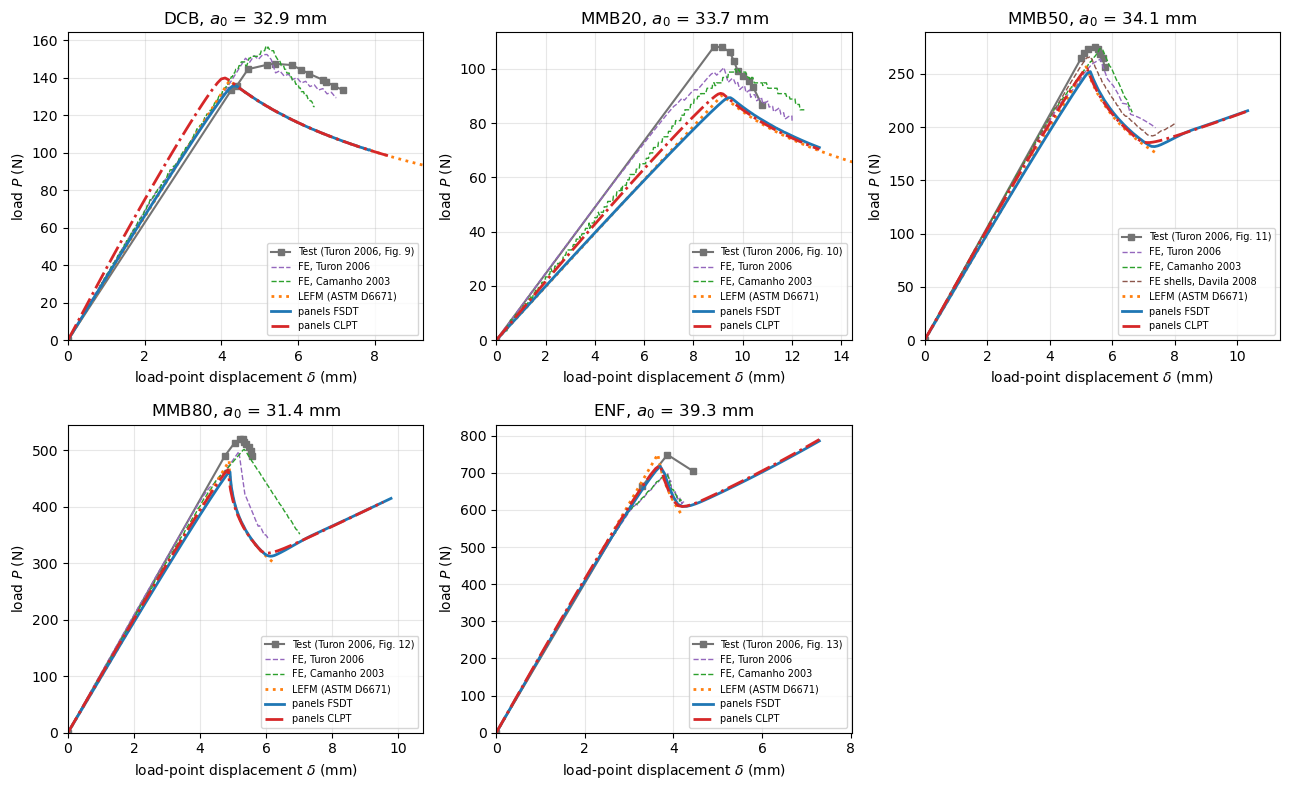

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
style = {'test': dict(color='0.45', marker='s', ms=4, lw=1.5),
         'FE': dict(lw=1, ls='--')}
fe_colour = {'FE, Turon 2006': dict(color='C4'), 'FE, Camanho 2003': dict(color='C2'),
             'FE shells, Davila 2008': dict(color='C5')}
for ax, (key, t) in zip(axes.flat, tests.items()):
    cs = {}
    for label, (d, p, kind) in curves[key].items():
        cs[label] = (d, p, dict(style[kind], **fe_colour.get(label, {})))
    cs['LEFM (ASTM D6671)'] = (lefm[key][0], lefm[key][1], dict(color='C1', ls=':', lw=2))
    for model, col in (('fsdt', 'C0'), ('clpt', 'C3')):
        res = runs.get('{0}_{1}'.format(key, model))
        if res is not None:
            cs['panels ' + model.upper()] = (np.r_[0., res['delta']], np.r_[0., res['P']],
                                             dict(color=col, lw=2, ls='-' if model == 'fsdt' else '-.'))
    mu.plot_test(ax, cs, title='{0}, $a_0$ = {1} mm'.format(key, t['a0']))
    ax.set_xlim(0, 1.1*max(np.nanmax(c[0]) for k, c in cs.items() if not k.startswith('LEFM')))
    ax.legend(fontsize=7)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [8]:
info = ['| run | status | increments | size | run time (min) | panels | machine |', '|---|---|---|---|---|---|---|']
for name, res in runs.items():
    info.append('| {0} | {1} | {2} | {3} | {4:.1f} | {5} ({6}) | {7} |'.format(
        name, res['status'], len(res['delta']), res['size'], res['time']/60, res['panels_version'],
        res['panels_commit'][:7], res['machine']))
display(Markdown('\n'.join(info)))

| run | status | increments | size | run time (min) | panels | machine |
|---|---|---|---|---|---|---|
| DCB_fsdt | stopped at delta = 7.8645 | 136 | 7520 | 77.7 | 0.16.0 (5aa6e01) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| DCB_clpt | finished | 85 | 4512 | 15.4 | 0.16.0 (5aa6e01) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB20_fsdt | finished | 146 | 7520 | 62.1 | 0.16.0 (5aa6e01) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB20_clpt | finished | 132 | 4512 | 15.8 | 0.16.0 (5aa6e01) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB50_fsdt | finished | 136 | 7120 | 69.7 | 0.16.0 (5aa6e01) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB50_clpt | finished | 104 | 4272 | 17.3 | 0.16.0 (5aa6e01) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB80_fsdt | finished | 350 | 7520 | 122.3 | 0.16.0 (5aa6e01) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB80_clpt | finished | 410 | 4512 | 90.6 | 0.16.0 (5aa6e01) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| ENF_fsdt | finished | 73 | 7120 | 28.6 | 0.16.0 (5aa6e01) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| ENF_clpt | finished | 73 | 4272 | 13.4 | 0.16.0 (5aa6e01) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |

## Discussion

- **panels and LEFM.** With the same inputs, the peak loads of `panels` are within 2% of the corrected beam theory for the DCB and the MMB at 20 and 50%, and 3-4% below it for the MMB at 80% and the ENF, where the process zone is longest and LEFM, which has no process zone, overpredicts the peak.
- **CLPT and FSDT arms.** The CLPT arms give peak loads 3.1% (DCB), 1.8% (MMB 20%), 1.0% (MMB 50%), 0.7% (MMB 80%) and 0.3% (ENF) above the FSDT arms: the transverse shear of the arms matters less as the mode II share grows.
- **Published results.** The FE peaks of Camanho et al. (2003) and Turon et al. (2006) lie 4-14% above `panels` for the DCB and the MMB, and the tests 6-20% above LEFM; for the ENF, LEFM matches the test of Turon et al. (2006) and the published FE peaks are about 3% below `panels`. Since LEFM and both `panels` models, which share no assumption other than the inputs, agree with one another, the differences lie in the references: inputs that are not reported, the three-dimensional models or the data reduction of the tests. The two papers give different experimental peaks for the DCB and the ENF. No input was adjusted to reduce these differences.
- **Penalty stiffness.** The published analyses use $K = 10^6$ N/mm$^3$, ten times the stiffness used here. The peak load of the DCB does not change for $k_I \geq 10^4$ N/mm$^3$ (A. Turon, C. G. Dávila, P. P. Camanho and J. Costa, *An engineering solution for mesh size effects in the simulation of delamination using cohesive zone models*, Eng. Fract. Mech. 2007; 74(10):1665-1682, https://doi.org/10.1016/j.engfracmech.2006.08.025, Fig. 9), so the stiffness is not expected to explain differences of this size.
- **Robustness.** The MMB at 80% snaps back after the peak and is traced with the control of the separation at the load line. The DCB with FSDT arms stops at $\delta$ = 7.86 mm, after the peak, with a crack length of 45.1 mm, when the increments are cut below the minimum; the other runs reach the last displacement.